# Deep learning: dense autoencoder

The encoder compresses each 98-feature window through a 32-unit layer into an eight-value representation. The decoder reconstructs the 98 inputs. Hidden layers use ReLU. Training minimizes mean squared reconstruction error with Adam, a learning rate of 0.001, 100 epochs, and batches of 16. The anomaly score is the mean squared reconstruction error of each window.

The optimizer sees only normal training windows. Normal validation windows select the checkpoint with the lowest reconstruction error. Both validation classes select the finite threshold maximizing true-positive rate minus false-positive rate. The held-out test set measures performance.

In [1]:
from pathlib import Path
import json
import subprocess
import sys

import matplotlib.pyplot as plt
import pandas as pd

root = Path.cwd()
if root.name == "notebooks":
    root = root.parent

subprocess.run([sys.executable, "-m", "src.deep_learning"], cwd=root, check=True)
results = root / "results"
metrics = json.loads((results / "dense_autoencoder_metrics.json").read_text())

## Inspect training and compare test results

The learning curve shows how reconstruction changes over training and where validation selected the checkpoint. The confusion matrix reports outcomes at the validation threshold. ROC AUC and balanced accuracy compare the autoencoder with the phase 3 models on the same split.

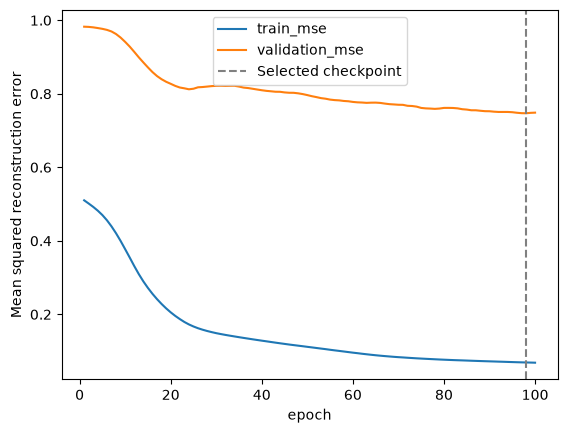

,Predicted normal,Predicted error
Actual normal,11,0
Actual error,655,168


device                              cpu
torch_version                2.15.0+cpu
best_epoch                           98
training_normal_windows              54
validation_normal_windows             6
threshold                      0.561945
training_seconds               3.334151
inference_median_seconds       0.000723
test_windows                        834
roc_auc                        0.708494
pr_auc                           0.9952
average_precision              0.995204
precision                           1.0
recall                         0.204131
f1                             0.339051
balanced_accuracy              0.602066
false_positive_rate                 0.0
tn                                   11
fp                                    0
fn                                  655
tp                                  168
Name: Dense autoencoder, dtype: object

,roc_auc,average_precision,balanced_accuracy,false_positive_rate
model,,,,
Robust deviation,0.581,0.990,0.542,0.364
Isolation Forest,0.567,0.991,0.532,0.455
Logistic Regression,0.627,0.993,0.450,0.909
Random Forest,0.801,0.996,0.775,0.182
Dense autoencoder,0.708,0.995,0.602,0.000


In [2]:
history = pd.read_csv(results / "dense_autoencoder_history.csv").set_index("epoch")
ax = history.plot(ylabel="Mean squared reconstruction error")
ax.axvline(metrics["best_epoch"], color="gray", linestyle="--", label="Selected checkpoint")
ax.legend()
plt.show()

confusion = pd.DataFrame(
    [[metrics["tn"], metrics["fp"]], [metrics["fn"], metrics["tp"]]],
    index=["Actual normal", "Actual error"],
    columns=["Predicted normal", "Predicted error"],
)
assert confusion.to_numpy().sum() == metrics["test_windows"]
display(confusion)
display(pd.Series(metrics, name="Dense autoencoder"))

comparison = pd.read_csv(results / "ml_detection.csv").set_index("model")
columns = ["roc_auc", "average_precision", "balanced_accuracy", "false_positive_rate"]
comparison.loc["Dense autoencoder", columns] = [metrics[key] for key in columns]
display(comparison[columns].round(3))

## Temporal comparison

Rebuild each 20-second sequence from the aligned Parquet table and the exact window boundaries used above. Scale the 49 per-second signals with normal training observations. Each temporal model uses Adam at 0.001 and batches of 16, with the lowest normal validation loss selecting the checkpoint from 100 epochs.

- **LSTM forecast** uses 24 gated hidden units to summarize the first 19 seconds and predict the final second.
- **LSTM autoencoder** compresses the full sequence to a 24-value state and uses a recurrent decoder to reconstruct every second. It scores mean squared reconstruction error.
- **TCN forecast** uses three dilated temporal convolutions (1, 2, 4) to learn patterns in the observed history. Its last activation uses a 15-second receptive field.
- **Transformer forecast** projects measurements to 24 channels and uses learned positions and four attention heads over the observed history. The final measurement is excluded from the model input.

Forecast models score the final second using mean squared prediction error. Timing covers batched scoring of the held-out windows in memory. All operating thresholds are chosen on validation data. The few normal windows come from a small number of independent runs and some overlap in time.

,best_epoch,threshold,roc_auc,pr_auc,precision,recall,f1,balanced_accuracy,false_positive_rate,tn,fp,fn,tp,train_seconds,inference_median_seconds
model,,,,,,,,,,,,,,,
lstm_forecast,81,2.1105,0.3811,0.9851,0.9851,0.0802,0.1483,0.4946,0.0909,10,1,757,66,0.8386,0.0057
lstm_autoencoder,25,2.2143,0.5534,0.9921,1.0000,0.0583,0.1102,0.5292,0.0000,11,0,775,48,1.4872,0.0132
tcn_forecast,39,2.0897,0.3875,0.9857,0.9877,0.0972,0.1770,0.5031,0.0909,10,1,743,80,1.1821,0.0035
transformer_forecast,67,2.1602,0.4639,0.9875,0.9821,0.0668,0.1251,0.4880,0.0909,10,1,768,55,1.7200,0.0115


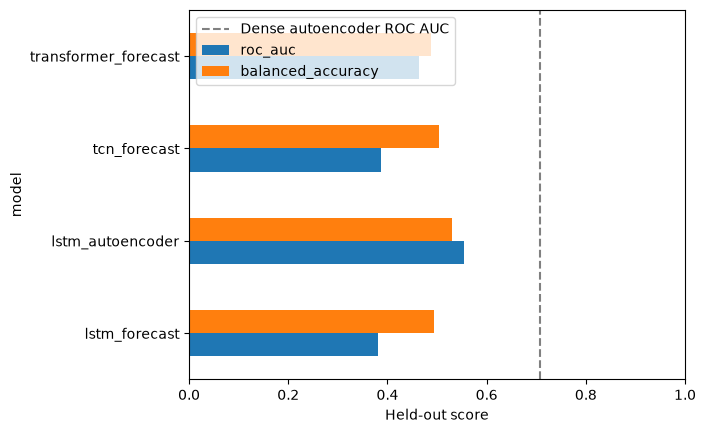

In [3]:
subprocess.run([sys.executable, "-m", "src.temporal_models"], cwd=root, check=True)
temporal = pd.read_csv(results / "temporal_model_metrics.csv").set_index("model")
assert (temporal[["tn", "fp", "fn", "tp"]].sum(axis=1) == metrics["test_windows"]).all()
display(temporal.round(4))
ax = temporal[["roc_auc", "balanced_accuracy"]].plot.barh(xlim=(0, 1))
ax.axvline(metrics["roc_auc"], color="gray", linestyle="--", label="Dense autoencoder ROC AUC")
ax.set_xlabel("Held-out score")
ax.legend()
plt.show()